# Comparing PINN runs

Loads every run saved by `save_run` in the training notebook and compares them.
Nothing is retrained here: each run's errors come from its `.json` file and its
predictions on the common test grid come from its `.pt` file.

**Before running:** set `RUNS_DIR` to the folder `save_run` wrote to, and make sure
the parameters below match the training notebook.

In [1]:
import os, glob, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

RUNS_DIR = "runs"   # folder used by save_run

## Parameters

These must match the training notebook. They are used to rebuild the common test
grid and the exact solution.

In [2]:
# Material and geometric parameters (same as training notebook)
E = 1e3
nu = 0.25
P = 2.0
L = 8.0
W = 2.0
b = 1.0
I = b * W**3 / 12.0

# Collocation grid size (sets the test grid)
Nx, Ny = 80, 40

# Common testing grid (same as save_run)
x_test = np.linspace(0, L, 2*Nx)
y_test = np.linspace(0, W, 2*Ny)
X_test, Y_test = np.meshgrid(x_test, y_test)
X_star_test = np.hstack((X_test.flatten()[:, None], Y_test.flatten()[:, None]))

# Exact solution (same as save_run)
def u_exact(x, y):
    term1 = (P * (y-W/2)) / (6 * E * I)
    term2 = (6 * L - 3 * x) * x + (2 + nu) * ((y-W/2)**2 - (W**2) / 4)
    return -term1 * term2

def v_exact(x, y):
    term1 = -(P) / (6 * E * I)
    term2 = 3 * nu * y**2 * (L - x) + (3 * L - x) * x**2
    return -term1 * term2

U_exact = u_exact(X_star_test[:, 0:1], X_star_test[:, 1:2]).reshape(2*Ny, 2*Nx)
V_exact = v_exact(X_star_test[:, 0:1], X_star_test[:, 1:2]).reshape(2*Ny, 2*Nx)

## Load all runs

In [3]:
def load_runs(folder=RUNS_DIR):
    """Returns (table of metadata, dict of run_name -> predictions)."""
    rows, preds = [], {}
    for pt_path in sorted(glob.glob(os.path.join(folder, "*.pt"))):
        checkpoint = torch.load(pt_path, map_location="cpu", weights_only=False)
        metadata = checkpoint["metadata"]
        run_name = metadata["run_name"]
        rows.append(metadata)
        preds[run_name] = {
            "U_pred": np.asarray(checkpoint["u_pred"]).reshape(2*Ny, 2*Nx),
            "V_pred": np.asarray(checkpoint["v_pred"]).reshape(2*Ny, 2*Nx),
            "X_star": checkpoint.get("X_star"),   # only if save_run stored it
        }
    df = pd.DataFrame(rows).sort_values("error_v").reset_index(drop=True)
    return df, preds

df, preds = load_runs()
print(f"Loaded {len(df)} runs from '{RUNS_DIR}'")
df

Loaded 13 runs from 'runs'


,run_name,mode,fit_epochs,fit_lr,final_fit_loss,error_u,error_v,start_frac,n_colloc,l-bfgs,...,c1,k2,c2,base_lr,ntk_every,n_ntk,lr_clip,lambda_max_0,lambda_max_final,final_lr
0,expressivity_test,expressivity_fit,20000.0,0.001,0.000152,0.009920,0.007336,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,original_strategy_plane_stress,original,NaN,NaN,NaN,0.055848,0.029426,1.0,3002.0,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,original_strategy,original,NaN,NaN,NaN,0.114960,0.093278,1.0,3002.0,True,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,strategy2_run4,ntk_lr,NaN,NaN,NaN,0.116897,0.094711,1.0,3002.0,True,...,NaN,NaN,NaN,0.0001,500.0,1200.0,10.0,9989.751481,11850.583792,0.000084
4,strategy2_run3,ntk_lr,NaN,NaN,NaN,0.116896,0.094715,1.0,3002.0,True,...,NaN,NaN,NaN,0.0001,500.0,700.0,10.0,9967.105980,11771.234189,0.000084
5,strategy2_run5,ntk_lr,NaN,NaN,NaN,0.116906,0.094721,1.0,3002.0,True,...,NaN,NaN,NaN,0.0001,500.0,3002.0,10.0,9927.863772,11781.262522,0.000084
6,strategy2_run2,ntk_lr,NaN,NaN,NaN,0.117670,0.094725,1.0,3002.0,True,...,NaN,NaN,NaN,0.0001,500.0,500.0,10.0,10027.905984,11889.143767,0.000084
7,strategy2_run1,ntk_lr,NaN,NaN,NaN,0.116941,0.094759,1.0,3002.0,True,...,NaN,NaN,NaN,0.0001,500.0,300.0,10.0,9915.060636,11803.970233,0.000084
8,strategy2_run6,ntk_lr,NaN,NaN,NaN,0.117129,0.094983,1.0,3002.0,True,...,NaN,NaN,NaN,0.0001,250.0,800.0,10.0,10012.230613,11941.218838,0.000084
9,strategy1_run4,NaN,NaN,NaN,NaN,0.121303,0.095134,0.1,2969.0,True,...,1.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Pick runs to compare

All runs by default. To compare a subset, list their names.

In [4]:
selected = list(df["run_name"])          # all runs
# selected = ["original_strategy", "strategy1"]   # or a subset

df_sel = df[df["run_name"].isin(selected)].reset_index(drop=True)
df_sel[["run_name", "n_colloc", "error_u", "error_v"]]

,run_name,n_colloc,error_u,error_v
0,expressivity_test,NaN,0.009920,0.007336
1,original_strategy_plane_stress,3002.0,0.055848,0.029426
2,original_strategy,3002.0,0.114960,0.093278
3,strategy2_run4,3002.0,0.116897,0.094711
4,strategy2_run3,3002.0,0.116896,0.094715
5,strategy2_run5,3002.0,0.116906,0.094721
6,strategy2_run2,3002.0,0.117670,0.094725
7,strategy2_run1,3002.0,0.116941,0.094759
8,strategy2_run6,3002.0,0.117129,0.094983
9,strategy1_run4,2969.0,0.121303,0.095134


## Relative L2 errors

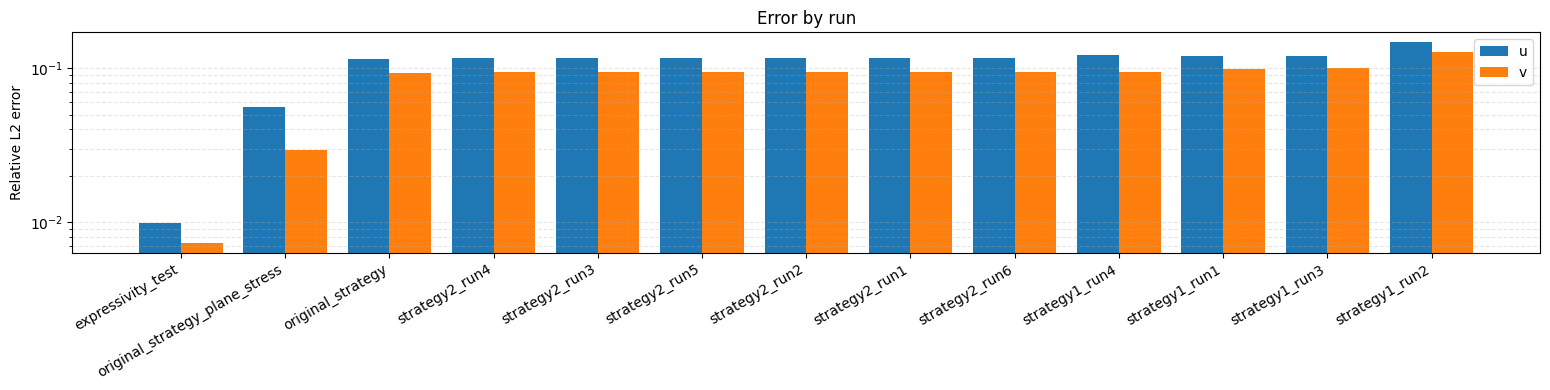

In [5]:
fig, ax = plt.subplots(figsize=(max(6, 1.2 * len(df_sel)), 4))
pos = np.arange(len(df_sel))
ax.bar(pos - 0.2, df_sel["error_u"], width=0.4, label="u")
ax.bar(pos + 0.2, df_sel["error_v"], width=0.4, label="v")
ax.set_xticks(pos)
ax.set_xticklabels(df_sel["run_name"], rotation=30, ha="right")
ax.set_yscale("log")
ax.set_ylabel("Relative L2 error")
ax.set_title("Error by run")
ax.legend()
ax.grid(True, axis="y", which="both", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Error vs number of collocation points

Runs further down-left are more accurate for fewer points.

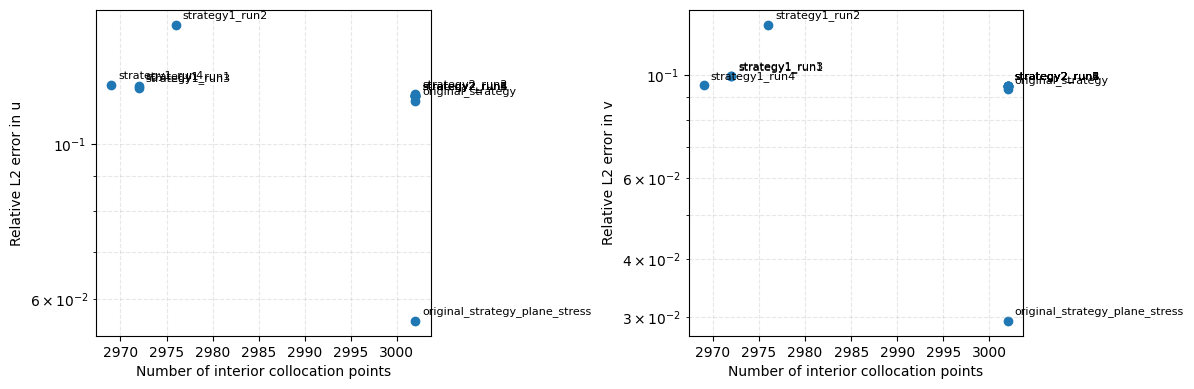

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, (err, label) in enumerate([("error_u", "u"), ("error_v", "v")]):
    ax[i].scatter(df_sel["n_colloc"], df_sel[err])
    for _, row in df_sel.iterrows():
        ax[i].annotate(row["run_name"], (row["n_colloc"], row[err]),
                       textcoords="offset points", xytext=(5, 5), fontsize=8)
    ax[i].set_yscale("log")
    ax[i].set_xlabel("Number of interior collocation points")
    ax[i].set_ylabel(f"Relative L2 error in {label}")
    ax[i].grid(True, which="both", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Error fields

Absolute error on the test grid, one row per run, on a shared color scale so runs
can be compared directly. If a run saved its collocation points, they are overlaid.

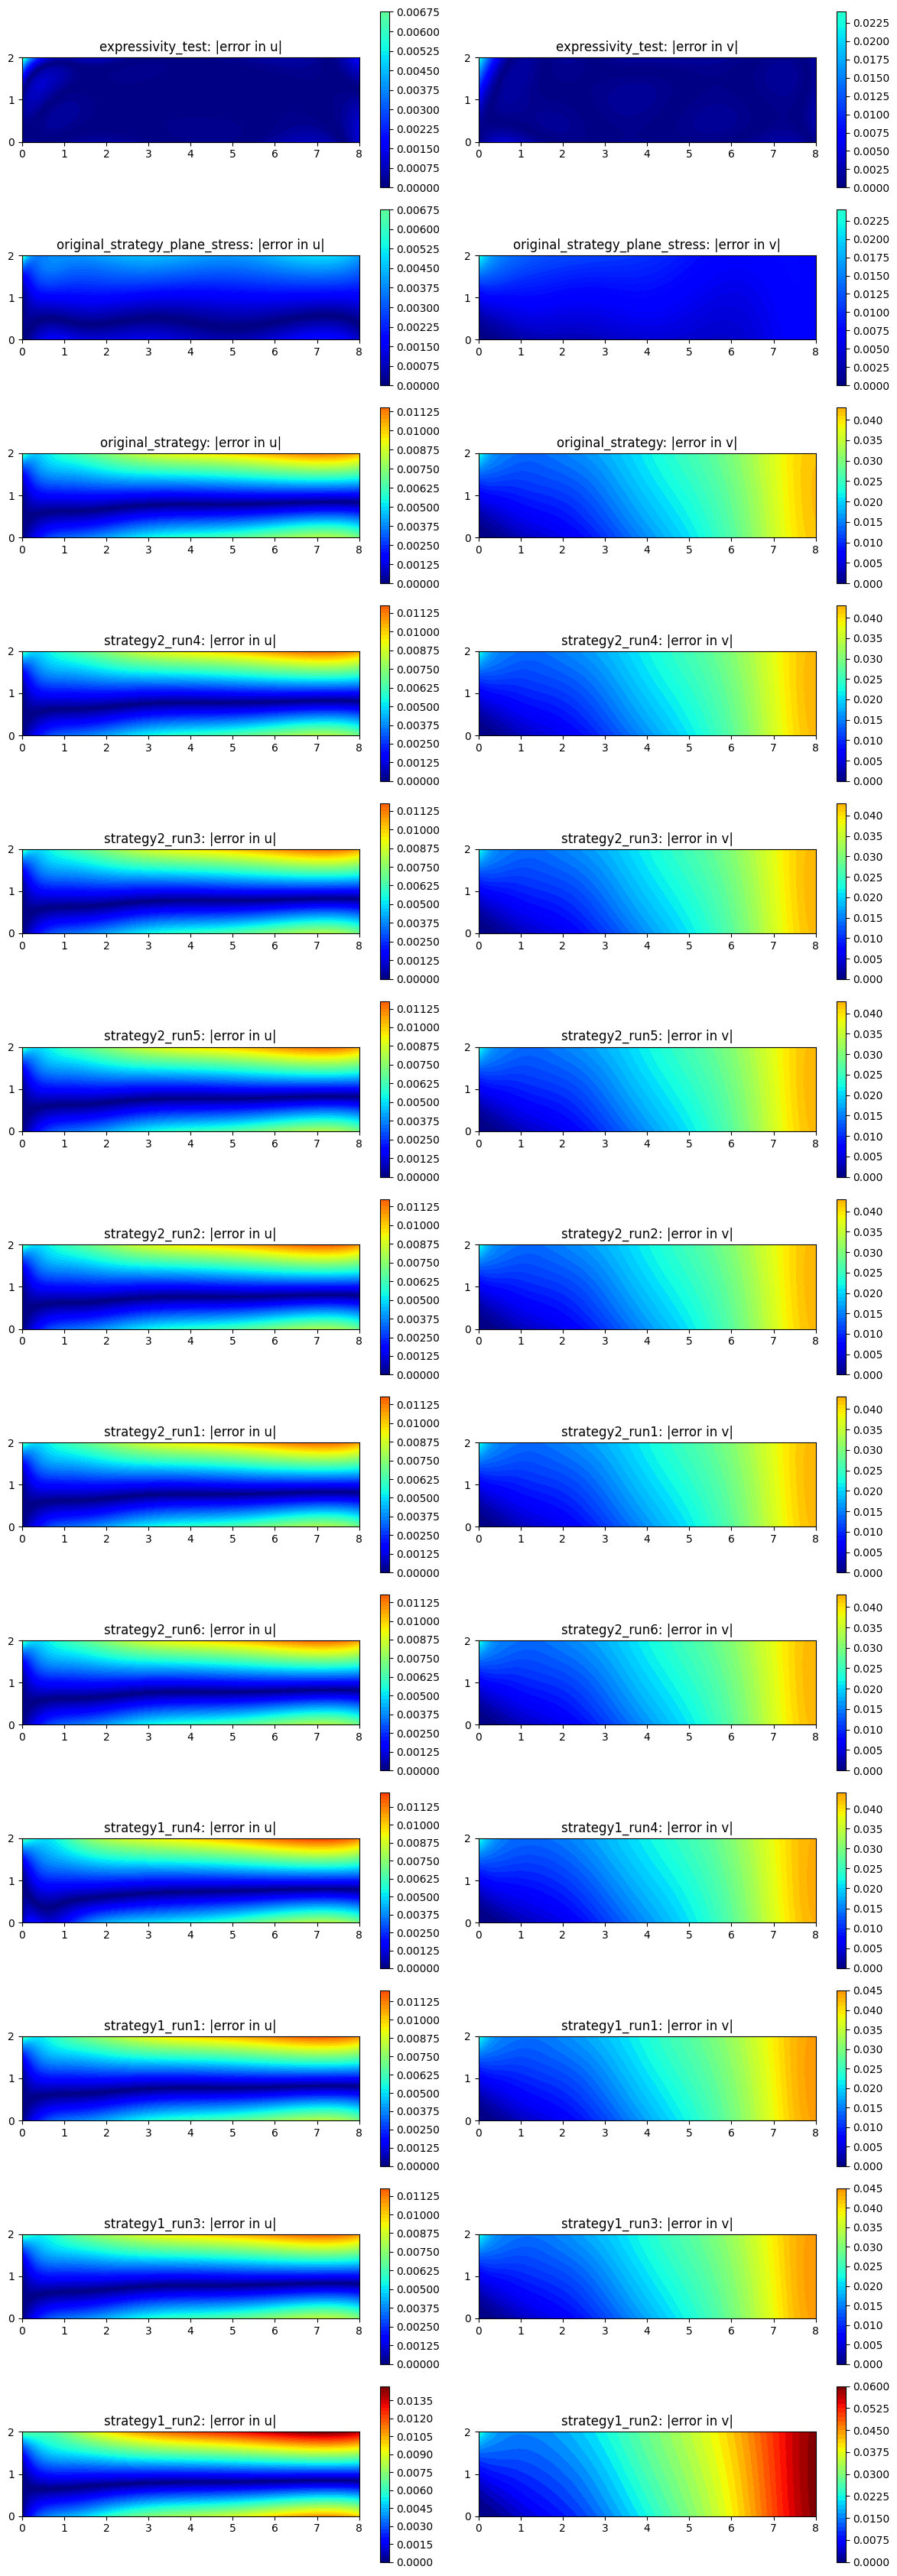

In [7]:
Error_U = {name: np.abs(U_exact - preds[name]["U_pred"]) for name in df_sel["run_name"]}
Error_V = {name: np.abs(V_exact - preds[name]["V_pred"]) for name in df_sel["run_name"]}
vmax_u = max(e.max() for e in Error_U.values())
vmax_v = max(e.max() for e in Error_V.values())

n = len(df_sel)
fig, ax = plt.subplots(n, 2, figsize=(12, 2.6 * n), squeeze=False)
for i, name in enumerate(df_sel["run_name"]):
    for j, (Err, vmax, label) in enumerate([(Error_U, vmax_u, "u"), (Error_V, vmax_v, "v")]):
        cf = ax[i, j].contourf(X_test, Y_test, Err[name], levels=50, cmap="jet", vmin=0, vmax=vmax)
        fig.colorbar(cf, ax=ax[i, j])
        X_star = preds[name]["X_star"]
        #if X_star is not None:
        #    ax[i, j].scatter(X_star[:, 0], X_star[:, 1], s=0.5, c="k", alpha=0.4)
        ax[i, j].set_title(f"{name}: |error in {label}|")
        ax[i, j].set_aspect("equal")
plt.tight_layout()
plt.show()

## Centerline deflection

v along the centerline (y closest to W/2) for each run vs the exact solution.

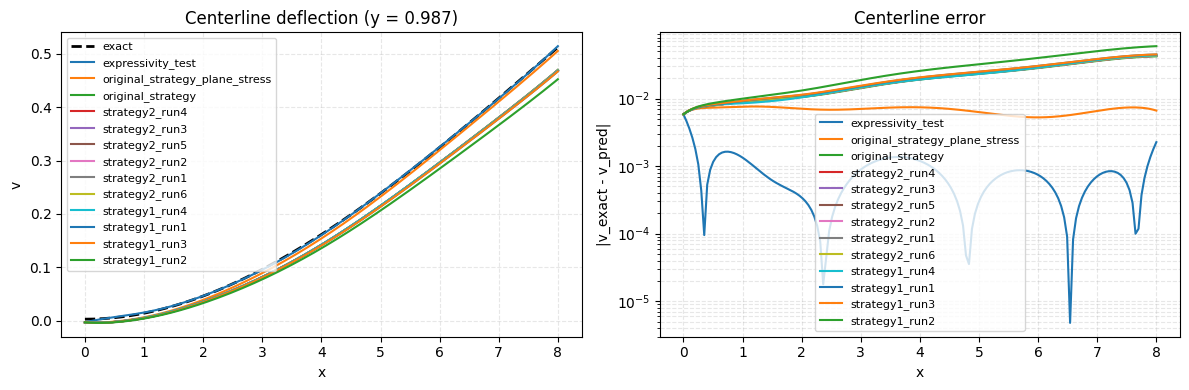

In [8]:
i_mid = np.argmin(np.abs(y_test - W/2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(x_test, V_exact[i_mid], "k--", lw=2, label="exact")
for name in df_sel["run_name"]:
    ax[0].plot(x_test, preds[name]["V_pred"][i_mid], label=name)
    ax[1].semilogy(x_test, np.abs(V_exact[i_mid] - preds[name]["V_pred"][i_mid]) + 1e-16, label=name)

ax[0].set_xlabel("x"); ax[0].set_ylabel("v")
ax[0].set_title(f"Centerline deflection (y = {y_test[i_mid]:.3f})")
ax[1].set_xlabel("x"); ax[1].set_ylabel("|v_exact - v_pred|")
ax[1].set_title("Centerline error")
for a in ax:
    a.legend(fontsize=8)
    a.grid(True, which="both", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Top edge comparison

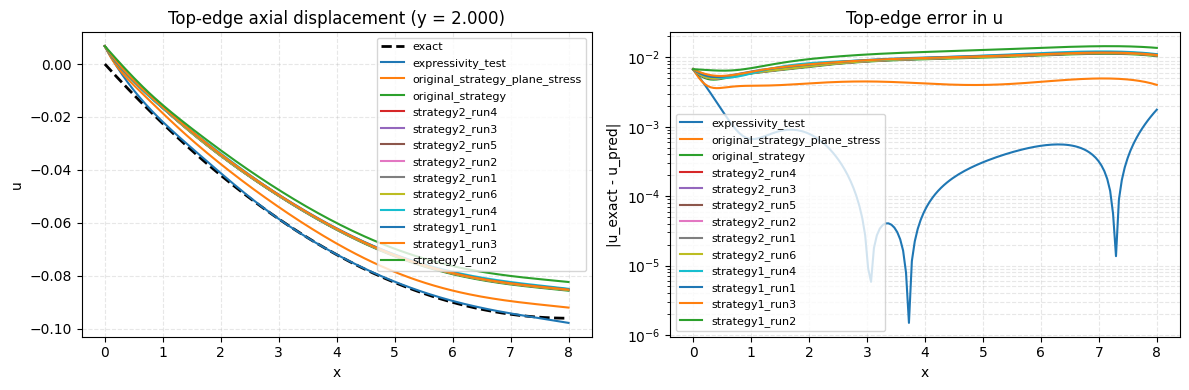

In [9]:
i_top = -1   # y_test[-1] = W, the top edge

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(x_test, U_exact[i_top], "k--", lw=2, label="exact")
for name in df_sel["run_name"]:
    ax[0].plot(x_test, preds[name]["U_pred"][i_top], label=name)
    ax[1].semilogy(x_test, np.abs(U_exact[i_top] - preds[name]["U_pred"][i_top]) + 1e-16, label=name)

ax[0].set_xlabel("x"); ax[0].set_ylabel("u")
ax[0].set_title(f"Top-edge axial displacement (y = {y_test[i_top]:.3f})")
ax[1].set_xlabel("x"); ax[1].set_ylabel("|u_exact - u_pred|")
ax[1].set_title("Top-edge error in u")
for a in ax:
    a.legend(fontsize=8)
    a.grid(True, which="both", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Bottom edge comparison

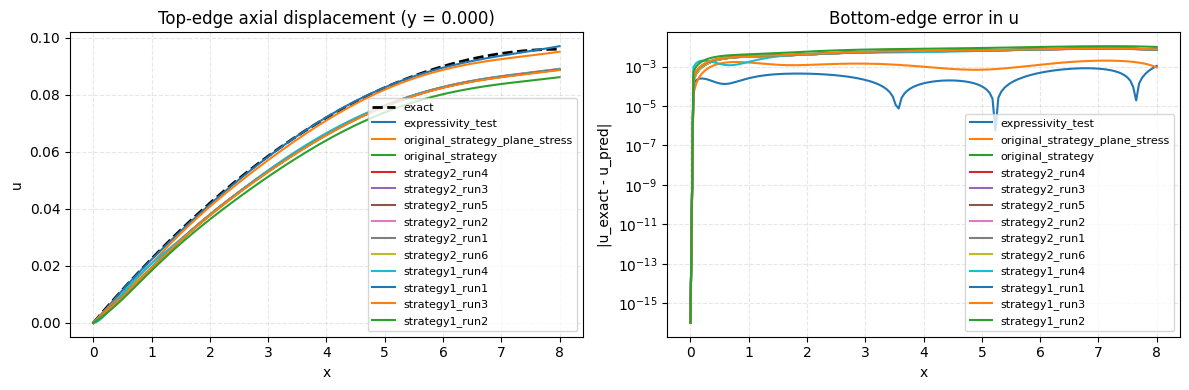

In [10]:
i_top = 0   # y_test[-1] = W, the top edge

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(x_test, U_exact[i_top], "k--", lw=2, label="exact")
for name in df_sel["run_name"]:
    ax[0].plot(x_test, preds[name]["U_pred"][i_top], label=name)
    ax[1].semilogy(x_test, np.abs(U_exact[i_top] - preds[name]["U_pred"][i_top]) + 1e-16, label=name)

ax[0].set_xlabel("x"); ax[0].set_ylabel("u")
ax[0].set_title(f"Top-edge axial displacement (y = {y_test[i_top]:.3f})")
ax[1].set_xlabel("x"); ax[1].set_ylabel("|u_exact - u_pred|")
ax[1].set_title("Bottom-edge error in u")
for a in ax:
    a.legend(fontsize=8)
    a.grid(True, which="both", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Head-to-head: two runs

Where run B is better (blue) or worse (red) than run A.

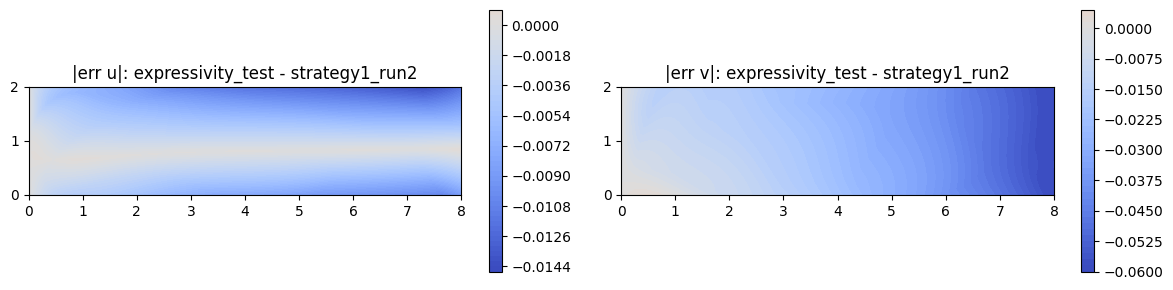

In [11]:
run_A = df_sel["run_name"].iloc[-1]   # worst in v by default
run_B = df_sel["run_name"].iloc[0]    # best in v by default
# run_A, run_B = "original_strategy", "strategy1"

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
for j, (Err, label) in enumerate([(Error_U, "u"), (Error_V, "v")]):
    diff = Err[run_B] - Err[run_A]
    lim = np.abs(diff).max()
    cf = ax[j].contourf(X_test, Y_test, diff, levels=50, cmap="coolwarm", vmin=-lim, vmax=lim)
    fig.colorbar(cf, ax=ax[j])
    ax[j].set_title(f"|err {label}|: {run_B} - {run_A}")
    ax[j].set_aspect("equal")
plt.tight_layout()
plt.show()